In [6]:
#Importación, carga del dataset y limpieza básica
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Cargar dataset de propinas (tips) desde Seaborn
df_propinas = sns.load_dataset("tips")

print("Dimensiones (filas, columnas):", df_propinas.shape)
print("\nValores nulos por columna:")
print(df_propinas.isnull().sum())
display(df_propinas.head())

Dimensiones (filas, columnas): (244, 7)

Valores nulos por columna:
total_bill    0
tip           0
sex           0
smoker        0
day           0
time          0
size          0
dtype: int64


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


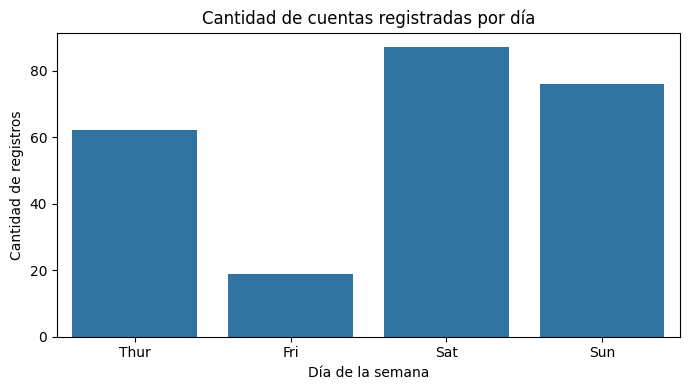

In [2]:
# 1. Gráfico de barras: cantidad de registros por día de la semana
plt.figure(figsize=(7, 4))
ax = sns.countplot(data=df_propinas, x="day", order=["Thur", "Fri", "Sat", "Sun"])
ax.set_title("Cantidad de cuentas registradas por día")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Cantidad de registros")
plt.tight_layout()
plt.show()

In [3]:
# Variable numérica principal a analizar
variable_numerica = "total_bill"

asimetria = df_propinas[variable_numerica].skew()
curtosis = df_propinas[variable_numerica].kurt()

print(f"Variable analizada: {variable_numerica}")
print(f"Asimetría (Skewness): {asimetria:.4f}")
print(f"Curtosis (Kurtosis): {curtosis:.4f}")

Variable analizada: total_bill
Asimetría (Skewness): 1.1332
Curtosis (Kurtosis): 1.2185


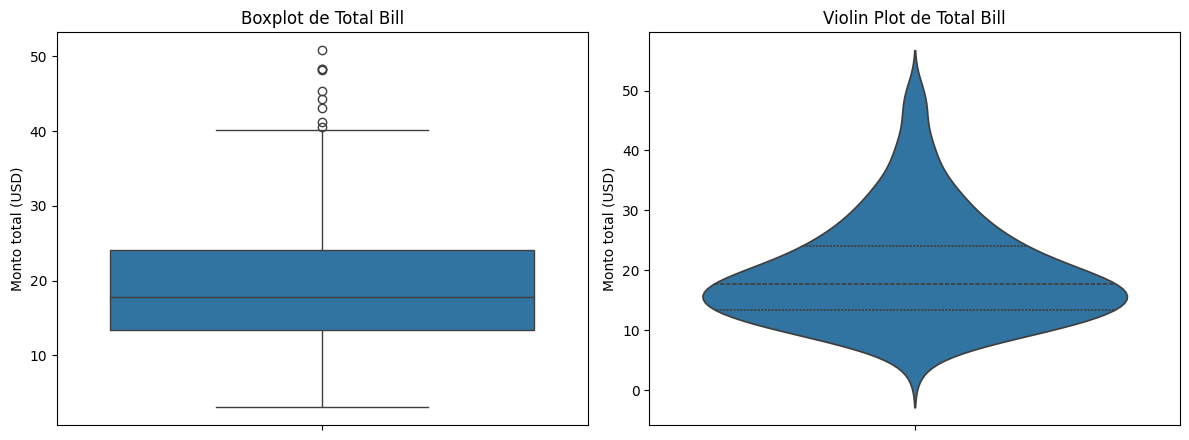

In [4]:
# 2. Boxplot y 3. Violin Plot lado a lado para 'total_bill'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Boxplot
sns.boxplot(data=df_propinas, y=variable_numerica, ax=axes[0])
axes[0].set_title("Boxplot de Total Bill")
axes[0].set_ylabel("Monto total (USD)")

# Violin Plot
sns.violinplot(data=df_propinas, y=variable_numerica, inner="quartile", ax=axes[1])
axes[1].set_title("Violin Plot de Total Bill")
axes[1].set_ylabel("Monto total (USD)")

plt.tight_layout()
plt.show()

In [5]:
# Cálculo del Rango Intercuartílico (IQR) para 'total_bill'
q1 = df_propinas[variable_numerica].quantile(0.25)
q3 = df_propinas[variable_numerica].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

outliers_df = df_propinas[
    (df_propinas[variable_numerica] < limite_inferior) |
    (df_propinas[variable_numerica] > limite_superior)
]

print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Límite inferior: {limite_inferior:.2f} | Límite superior: {limite_superior:.2f}")
print(f"Cantidad de outliers detectados: {len(outliers_df)}")
display(outliers_df)

Q1: 13.35 | Q3: 24.13 | IQR: 10.78
Límite inferior: -2.82 | Límite superior: 40.30
Cantidad de outliers detectados: 9


,total_bill,tip,sex,smoker,day,time,size
59,48.27,6.73,Male,No,Sat,Dinner,4
102,44.30,2.50,Female,Yes,Sat,Dinner,3
142,41.19,5.00,Male,No,Thur,Lunch,5
156,48.17,5.00,Male,No,Sun,Dinner,6
170,50.81,10.00,Male,Yes,Sat,Dinner,3
182,45.35,3.50,Male,Yes,Sun,Dinner,3
184,40.55,3.00,Male,Yes,Sun,Dinner,2
197,43.11,5.00,Female,Yes,Thur,Lunch,4
212,48.33,9.00,Male,No,Sat,Dinner,4
